# K-Means Clustering on Mall Dataset

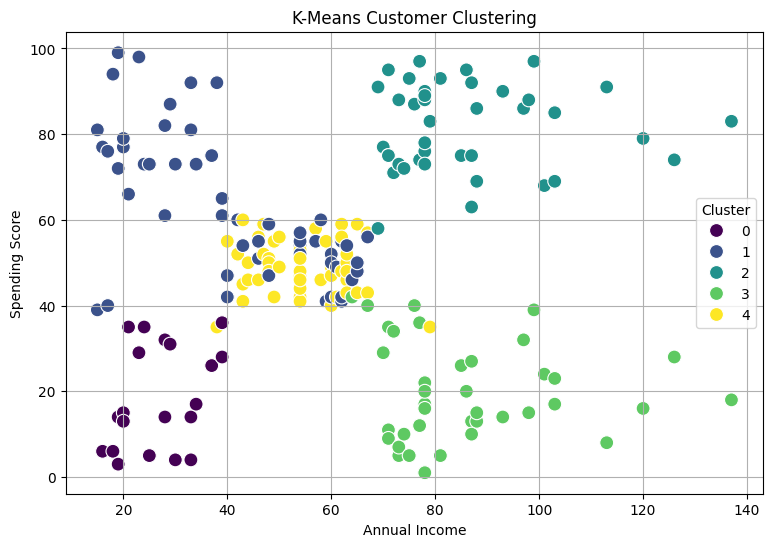


Cluster Summary:
           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        46.25               26.75                   18.35
1        25.19               41.09                   62.24
2        32.88               86.10                   81.53
3        39.87               86.10                   19.36
4        55.64               54.38                   48.85


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


df = pd.read_csv("/content/Mall_Customers (1).csv")


df.columns = df.columns.str.strip()

X = df[
    [
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].copy()

X = X.apply(pd.to_numeric, errors="coerce")
X = X.dropna()


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Add Cluster Labels
X["Cluster"] = clusters

# Visualize Clusters Using Original Features
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("K-Means Customer Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.grid()
plt.show()


print("\nCluster Summary:")
print(X.groupby("Cluster").mean().round(2))


#Visualize clusters with PCA

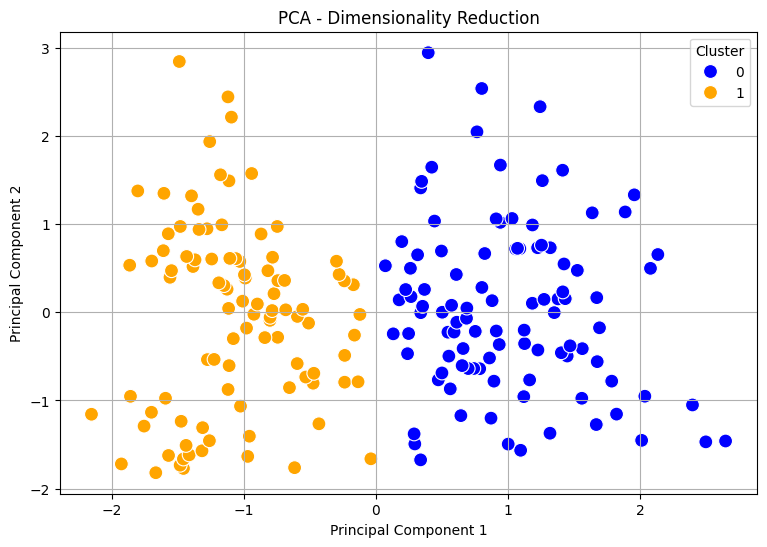

Explained Variance Ratio:
[0.44266167 0.33308378]

Total Explained Variance:
77.57 %


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


df = pd.read_csv("/content/Mall_Customers (1).csv")


df.columns = df.columns.str.strip()

X = df[
    [
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].copy()

X = X.apply(pd.to_numeric, errors="coerce")
X = X.dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA: Reduce 3 Features to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
pca_df["Cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Cluster",
    palette={0: "blue", 1: "orange"},
    s=100
)

plt.title("PCA - Dimensionality Reduction")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid()
plt.show()

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


#K-Means – Elbow Method and Silhouette Score Method

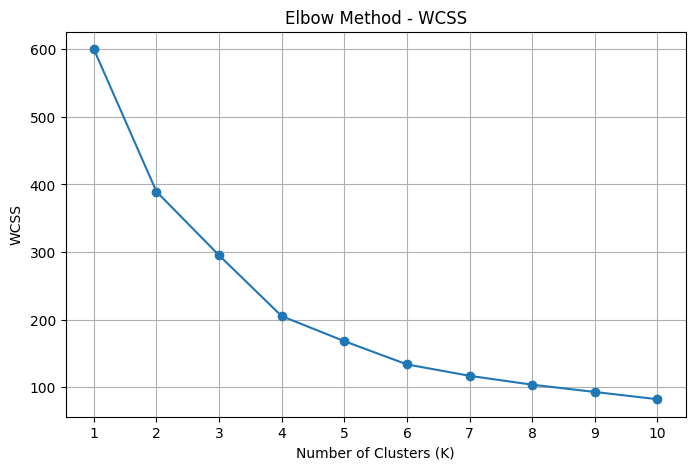

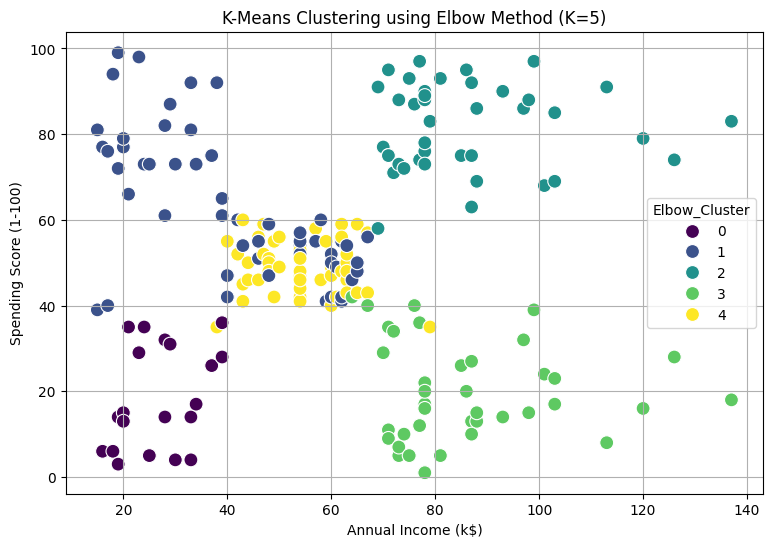

Elbow Method Cluster Summary:
                 Age  Annual Income (k$)  Spending Score (1-100)
Elbow_Cluster                                                   
0              46.25               26.75                   18.35
1              25.19               41.09                   62.24
2              32.88               86.10                   81.53
3              39.87               86.10                   19.36
4              55.64               54.38                   48.85


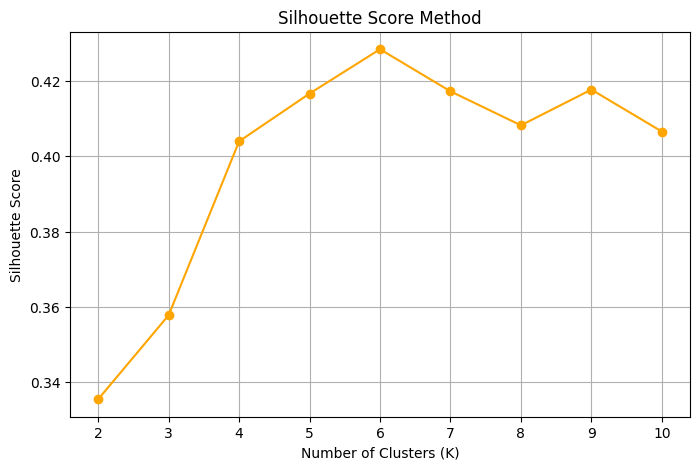


Best K using Silhouette Score: 6
Highest Silhouette Score: 0.4284


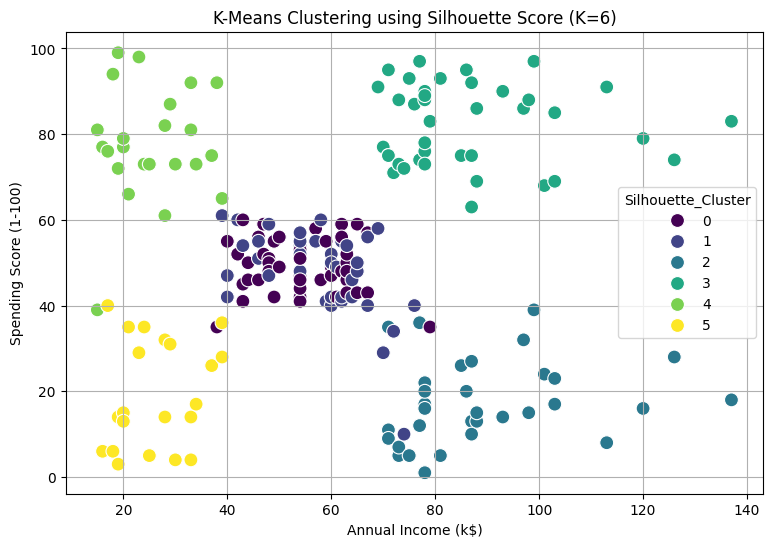


Silhouette Method Cluster Summary:
                      Age  Annual Income (k$)  Spending Score (1-100)
Silhouette_Cluster                                                   
0                   56.33               54.27                   49.07
1                   26.79               57.10                   48.13
2                   41.94               88.94                   16.97
3                   32.69               86.54                   82.13
4                   25.00               25.26                   77.61
5                   45.52               26.29                   19.38

Method Comparison:
          Method  Optimal K  Silhouette Score
    Elbow Method          5            0.4166
Silhouette Score          6            0.4284


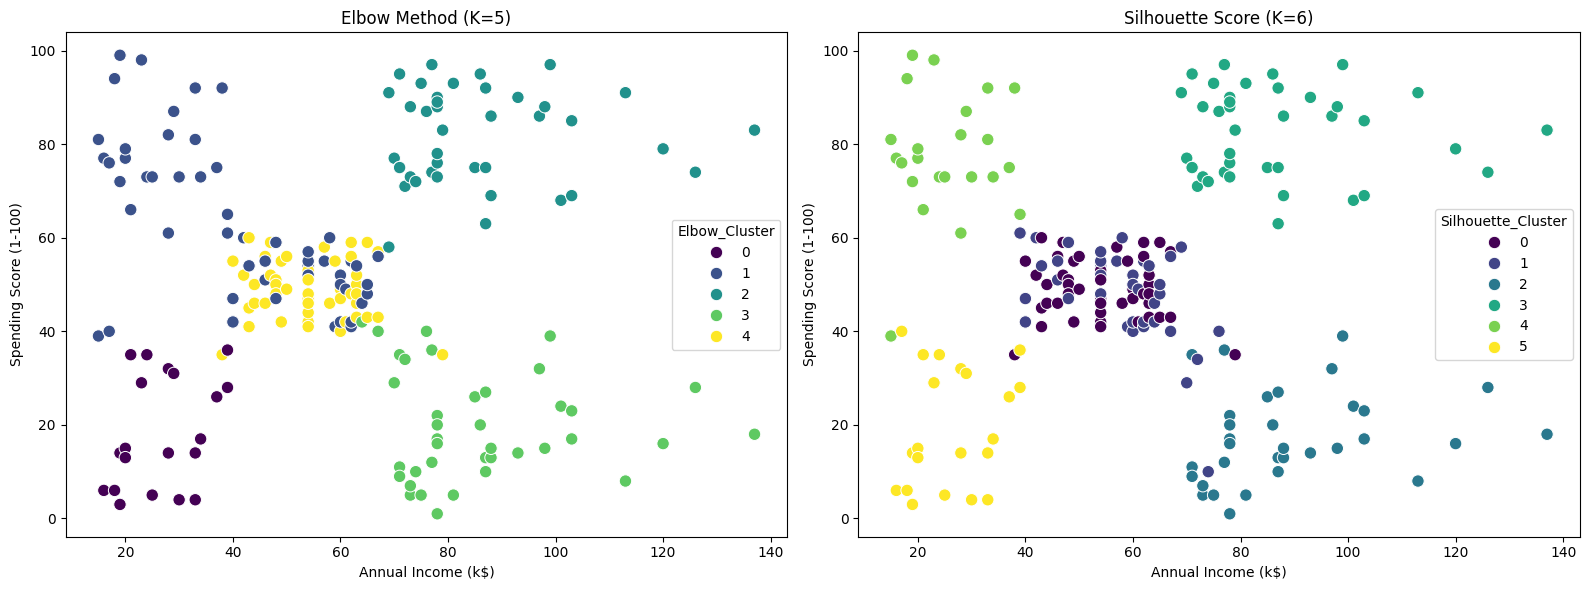

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


df = pd.read_csv("/content/Mall_Customers (1).csv")
df.columns = df.columns.str.strip()

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].apply(pd.to_numeric, errors="coerce").dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method - WCSS")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

# Apply K-Means using Elbow Method
elbow_k = 5

elbow_model = KMeans(n_clusters=elbow_k, random_state=42, n_init=10)
X["Elbow_Cluster"] = elbow_model.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Elbow_Cluster",
    palette="viridis",
    s=100
)
plt.title(f"K-Means Clustering using Elbow Method (K={elbow_k})")
plt.grid()
plt.show()

print("Elbow Method Cluster Summary:")
print(X.groupby("Elbow_Cluster")[features].mean().round(2))


silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker="o", color="orange")
plt.title("Silhouette Score Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid()
plt.show()

# Find Best K
silhouette_k = range(2, 11)[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

print("\nBest K using Silhouette Score:", silhouette_k)
print("Highest Silhouette Score:", round(best_score, 4))

# Apply K-Means using Silhouette Score
silhouette_model = KMeans(
    n_clusters=silhouette_k,
    random_state=42,
    n_init=10
)

X["Silhouette_Cluster"] = silhouette_model.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Silhouette_Cluster",
    palette="viridis",
    s=100
)
plt.title(f"K-Means Clustering using Silhouette Score (K={silhouette_k})")
plt.grid()
plt.show()

print("\nSilhouette Method Cluster Summary:")
print(X.groupby("Silhouette_Cluster")[features].mean().round(2))


comparison = pd.DataFrame({
    "Method": ["Elbow Method", "Silhouette Score"],
    "Optimal K": [elbow_k, silhouette_k],
    "Silhouette Score": [
        silhouette_score(
            X_scaled,
            X["Elbow_Cluster"]
        ),
        best_score
    ]
})

print("\nMethod Comparison:")
print(comparison.round(4).to_string(index=False))


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Elbow_Cluster",
    palette="viridis",
    s=80,
    ax=axes[0]
)
axes[0].set_title(f"Elbow Method (K={elbow_k})")

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Silhouette_Cluster",
    palette="viridis",
    s=80,
    ax=axes[1]
)
axes[1].set_title(f"Silhouette Score (K={silhouette_k})")

plt.tight_layout()
plt.show()


#PCA - Elbow Method and Silhouette Score Method

Explained Variance Ratio:
[0.4427 0.3331 0.2243]

Cumulative Explained Variance:
[0.4427 0.7757 1.    ]

Total Variance Explained by 2 Components:
77.57 %


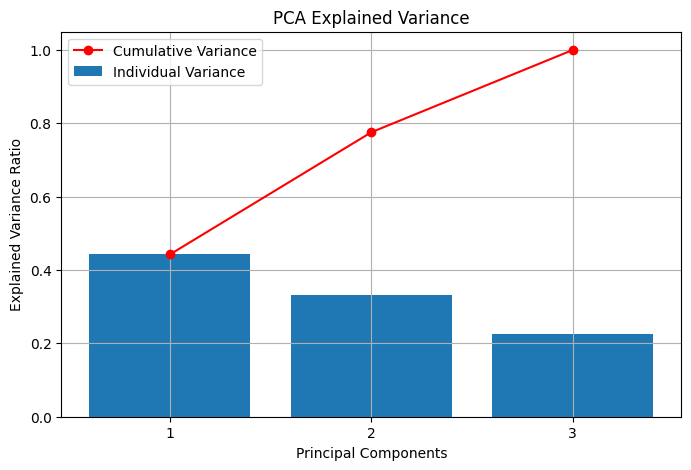


PCA Transformed Data:
        PC1       PC2
0 -0.615720 -1.763481
1 -1.665793 -1.820747
2  0.337862 -1.674799
3 -1.456573 -1.772430
4 -0.038465 -1.662740

Variance Preserved:
77.57 %


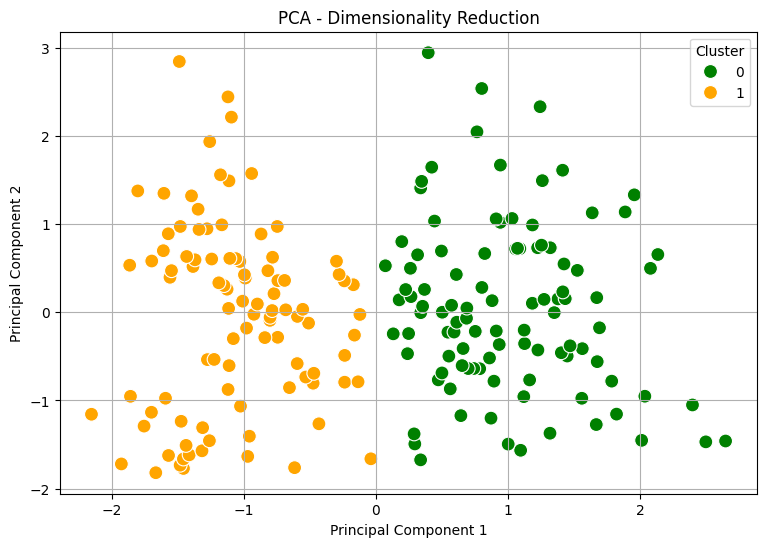


PCA Component Loadings:
                           PC1     PC2
Age                     0.7064  0.0301
Annual Income (k$)     -0.0480  0.9988
Spending Score (1-100) -0.7062 -0.0378


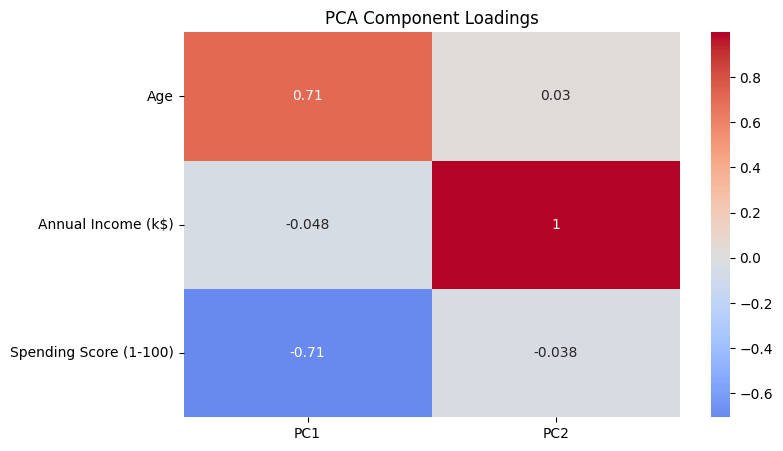

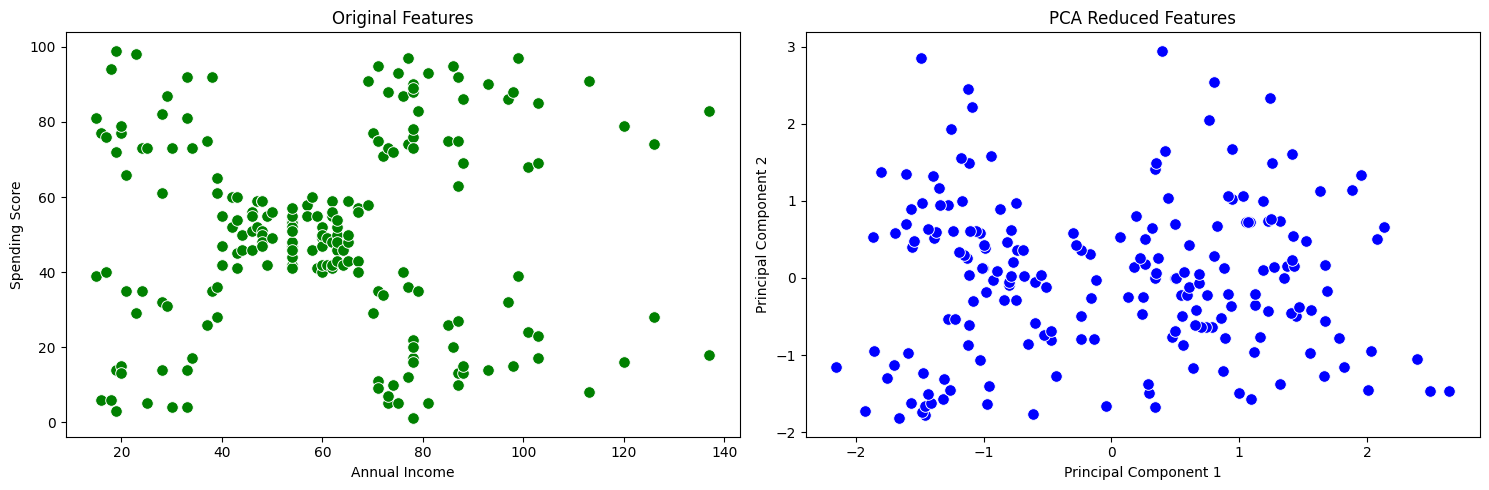


PCA Summary
---------------------------
Original Number of Features: 3
Reduced Number of Features: 2
Original Data Shape: (200, 3)
Reduced Data Shape: (200, 2)
Information Preserved: 77.57 %


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("/content/Mall_Customers (1).csv")
df.columns = df.columns.str.strip()

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].apply(pd.to_numeric, errors="coerce").dropna()


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained Variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

print("Explained Variance Ratio:")
print(explained_variance.round(4))

print("\nCumulative Explained Variance:")
print(cumulative_variance.round(4))

print("\nTotal Variance Explained by 2 Components:")
print(round(cumulative_variance[1] * 100, 2), "%")

plt.figure(figsize=(8, 5))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    label="Individual Variance"
)
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    color="red",
    label="Cumulative Variance"
)

plt.title("PCA Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.grid()
plt.show()

#  Reduce 3 Features to 2 Components

pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca_2,
    columns=["PC1", "PC2"],
    index=X.index
)

print("\nPCA Transformed Data:")
print(pca_df.head())

print("\nVariance Preserved:")
print(round(pca_2.explained_variance_ratio_.sum() * 100, 2), "%")


kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
pca_df["Cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette={0: "green", 1: "orange"},
    s=100
)

plt.title("PCA - Dimensionality Reduction")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid()
plt.show()


loadings = pd.DataFrame(
    pca_2.components_.T,
    columns=["PC1", "PC2"],
    index=features
)

print("\nPCA Component Loadings:")
print(loadings.round(4))

plt.figure(figsize=(8, 5))
sns.heatmap(
    loadings,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("PCA Component Loadings")
plt.show()

#  Original Features vs PCA


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    x=X["Annual Income (k$)"],
    y=X["Spending Score (1-100)"],
    ax=axes[0],
    color="green",
    s=70
)
axes[0].set_title("Original Features")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Spending Score")

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    ax=axes[1],
    color="blue",
    s=70
)
axes[1].set_title("PCA Reduced Features")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

print("\nPCA Summary")
print("---------------------------")
print("Original Number of Features:", X.shape[1])
print("Reduced Number of Features:", X_pca_2.shape[1])
print("Original Data Shape:", X_scaled.shape)
print("Reduced Data Shape:", X_pca_2.shape)
print(
    "Information Preserved:",
    round(pca_2.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Using GridSearchCV to tune classifiers

Fitting 5 folds for each of 135 candidates, totalling 675 fits

Best Parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5}

Best Cross-Validation Score:
0.9385

Model Performance Comparison:
                Model  Accuracy
Default Decision Tree  0.912281
  Tuned Decision Tree  0.921053

Accuracy Improvement:
0.88 %

Classification Report:
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



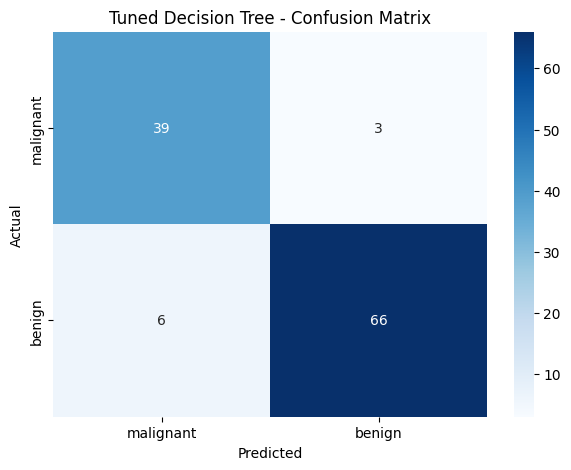

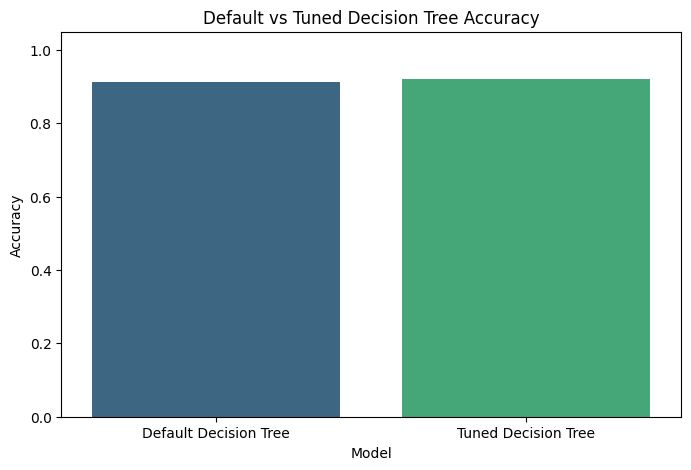

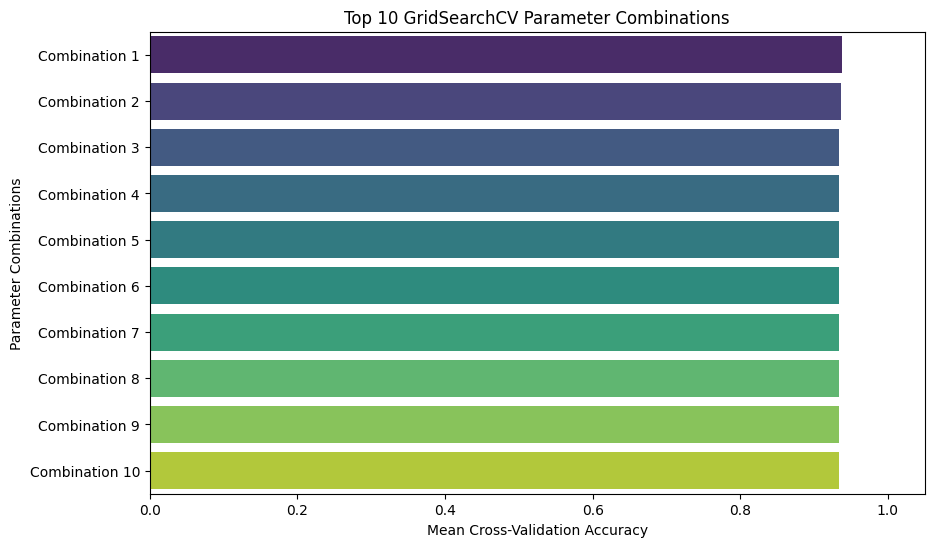

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Evaluate Default Model
pipeline.fit(X_train, y_train)
baseline_predictions = pipeline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

# Define Hyperparameter Grid
param_grid = {
    "classifier__criterion": ["gini", "entropy", "log_loss"],
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

# Apply GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)


print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Score:")
print(round(grid_search.best_score_, 4))

# Evaluate Tuned Model
best_model = grid_search.best_estimator_
tuned_predictions = best_model.predict(X_test)
tuned_accuracy = accuracy_score(y_test, tuned_predictions)

comparison = pd.DataFrame({
    "Model": ["Default Decision Tree", "Tuned Decision Tree"],
    "Accuracy": [baseline_accuracy, tuned_accuracy]
})

print("\nModel Performance Comparison:")
print(comparison.to_string(index=False))

print("\nAccuracy Improvement:")
print(round((tuned_accuracy - baseline_accuracy) * 100, 2), "%")


print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_predictions,
    target_names=data.target_names
))


cm = confusion_matrix(y_test, tuned_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.title("Tuned Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Visualize Default vs Tuned Accuracy
plt.figure(figsize=(8, 5))
sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="viridis",
    legend=False
)
plt.title("Default vs Tuned Decision Tree Accuracy")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.show()

# Visualize Top 10 GridSearch Combinations
results = pd.DataFrame(grid_search.cv_results_)
top_results = results.sort_values(
    by="mean_test_score",
    ascending=False
).head(10).copy()

top_results["Configuration"] = [
    f"Combination {i+1}" for i in range(len(top_results))
]

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_results,
    x="mean_test_score",
    y="Configuration",
    hue="Configuration",
    palette="viridis",
    legend=False
)
plt.title("Top 10 GridSearchCV Parameter Combinations")
plt.xlabel("Mean Cross-Validation Accuracy")
plt.ylabel("Parameter Combinations")
plt.xlim(0, 1.05)
plt.show()


### Explanation of GridSearchCV Tuning Results

GridSearchCV was applied to the Decision Tree Classifier using the Breast Cancer dataset to identify the optimal hyperparameters. Different combinations of criterion, maximum depth, minimum samples split, and minimum samples leaf were evaluated using 5-fold cross-validation.

The best hyperparameter combination was selected based on the highest average cross-validation accuracy. The tuned model was then evaluated on the test dataset and compared with the default Decision Tree model.

Performance was analyzed using accuracy scores, a confusion matrix, and visualizations of the top 10 parameter combinations.

**Conclusion:** GridSearchCV helps identify suitable hyperparameters for the Decision Tree Classifier. Comparing the default and tuned models shows whether hyperparameter optimization improves classification performance and generalization.